In [1]:
source('../R/preamble.R')
#library(ggh4x)
library(ggplotify)
library(magick)

Linking to ImageMagick 7.1.2.15
Enabled features: freetype, fftw, heic, webp
Disabled features: cairo, fontconfig, ghostscript, lcms, pango, raw, rsvg, x11



In [4]:
empty <- ggplot() + theme_void()

#letters = element_text(size = 12, hjust=0, vjust=0, face = 'bold', margin = margin(-5,-5,0,0))
letters = function(...){element_text(size = 12, hjust=0, vjust=0, face = 'bold', margin = margin(...))}

small_titles = theme(axis.title = element_text(size=10))
small_text = theme(axis.text = element_text(size=8))

In [5]:
stickiness = readRDS('panels/stickiness.rds')
fims = readRDS('panels/fims.rds')
tau = readRDS('panels/doubling_times.rds')

fimh = readRDS('../analysis/genomics/10_mutation_traces/Plots/GG/fimH_mutation_traces_pure_pops.rds')

Warning message:
“The `scale_name` argument of `discrete_scale()` is deprecated as of ggplot2 3.5.0.”


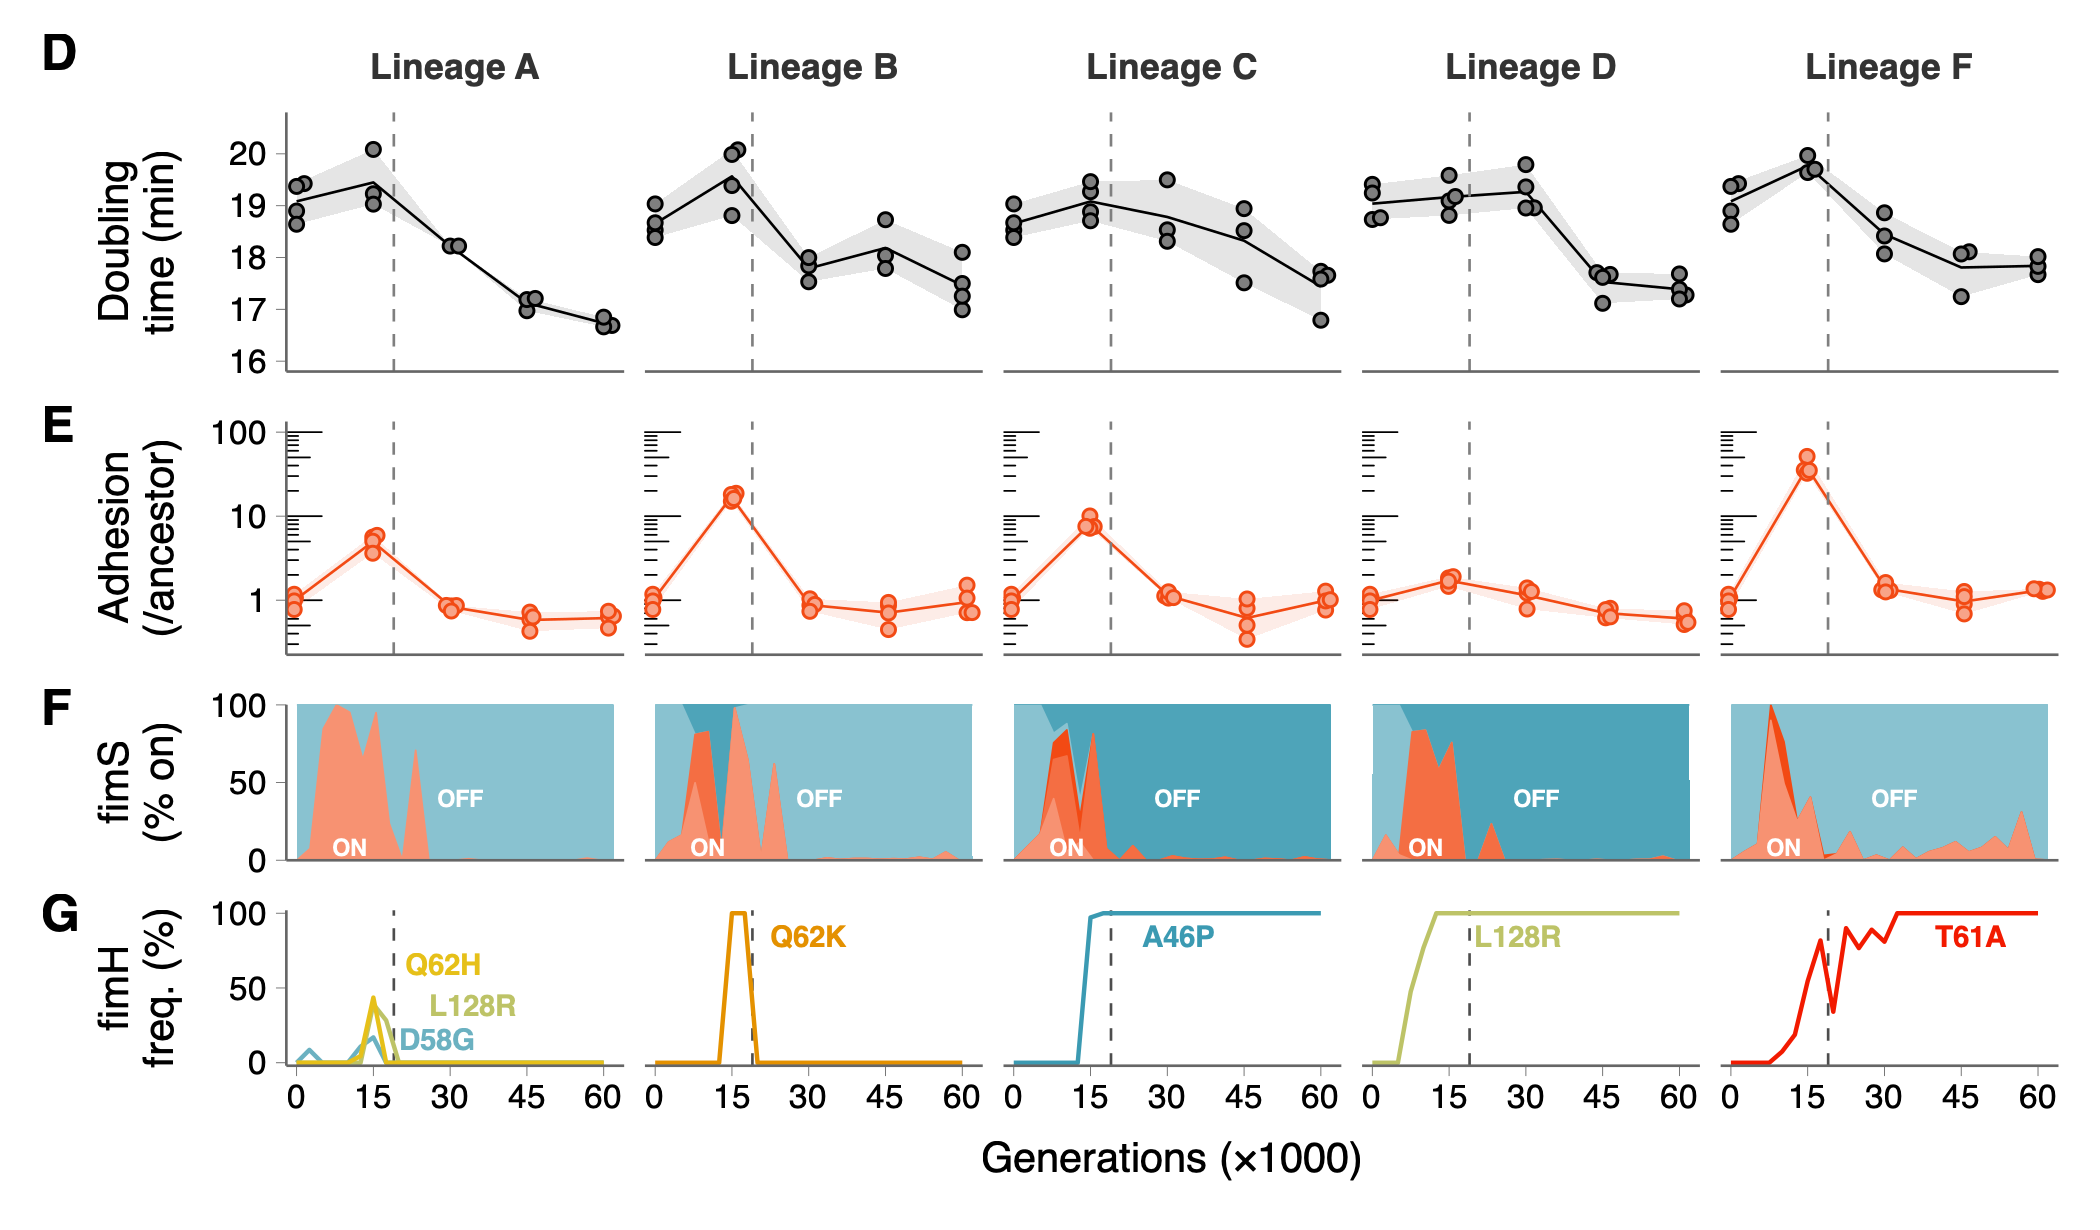

In [6]:
no_x = theme(axis.text.x=eb, axis.ticks.x=eb)

bottom_left = (
    (tau + no_x + ylab('Doubling\ntime (min)') + labs(tag='D')) +
    (stickiness + no_x + labs(tag='E')) +
    (fims + no_x + ylab('fimS\n(% on)') + labs(tag='F')) +
    (fimh + ylab('fimH\nfreq. (%)') + labs(tag='G'))
) +
    plot_layout(
        ncol = 1,
        heights = c(1, 0.9, 0.6, 0.6),
        axis = 'collect'
    )

size(4.1, 7)
bottom_left & theme(plot.tag = letters(-5, 5, -5, 0))

psave('output/machine_overview')

# Convergence and mutators

In [5]:
overview = readRDS('../analysis/genomics/10_mutation_traces/Plots/GG/experiment_overview.rds')

A_takeover_sspA = readRDS('../analysis/genomics/10_mutation_traces/Plots/GG/A_takeover_sspA.rds')
domestication_scars = readRDS('../analysis/genomics/10_mutation_traces/Plots/GG/domestication_scars.rds')

daf_mutators =readRDS('../analysis/genomics/06_mutators/Plots/GG/daf_plot_mutators.rds')
daf_nonmutators =readRDS('../analysis/genomics/06_mutators/Plots/GG/daf_plot_nonmutators.rds')

ig_enrichment = readRDS('../analysis/genomics/07_mutation_statistics/Plots/GG/ig_enrichment.rds') + small_text + small_titles
ess_enrichment = readRDS('../analysis/genomics/07_mutation_statistics/Plots/GG/ess_enrichment.rds') + small_text + small_titles
syn_enrichment = readRDS('../analysis/genomics/07_mutation_statistics/Plots/GG/syn_enrichment.rds') + small_text + small_titles

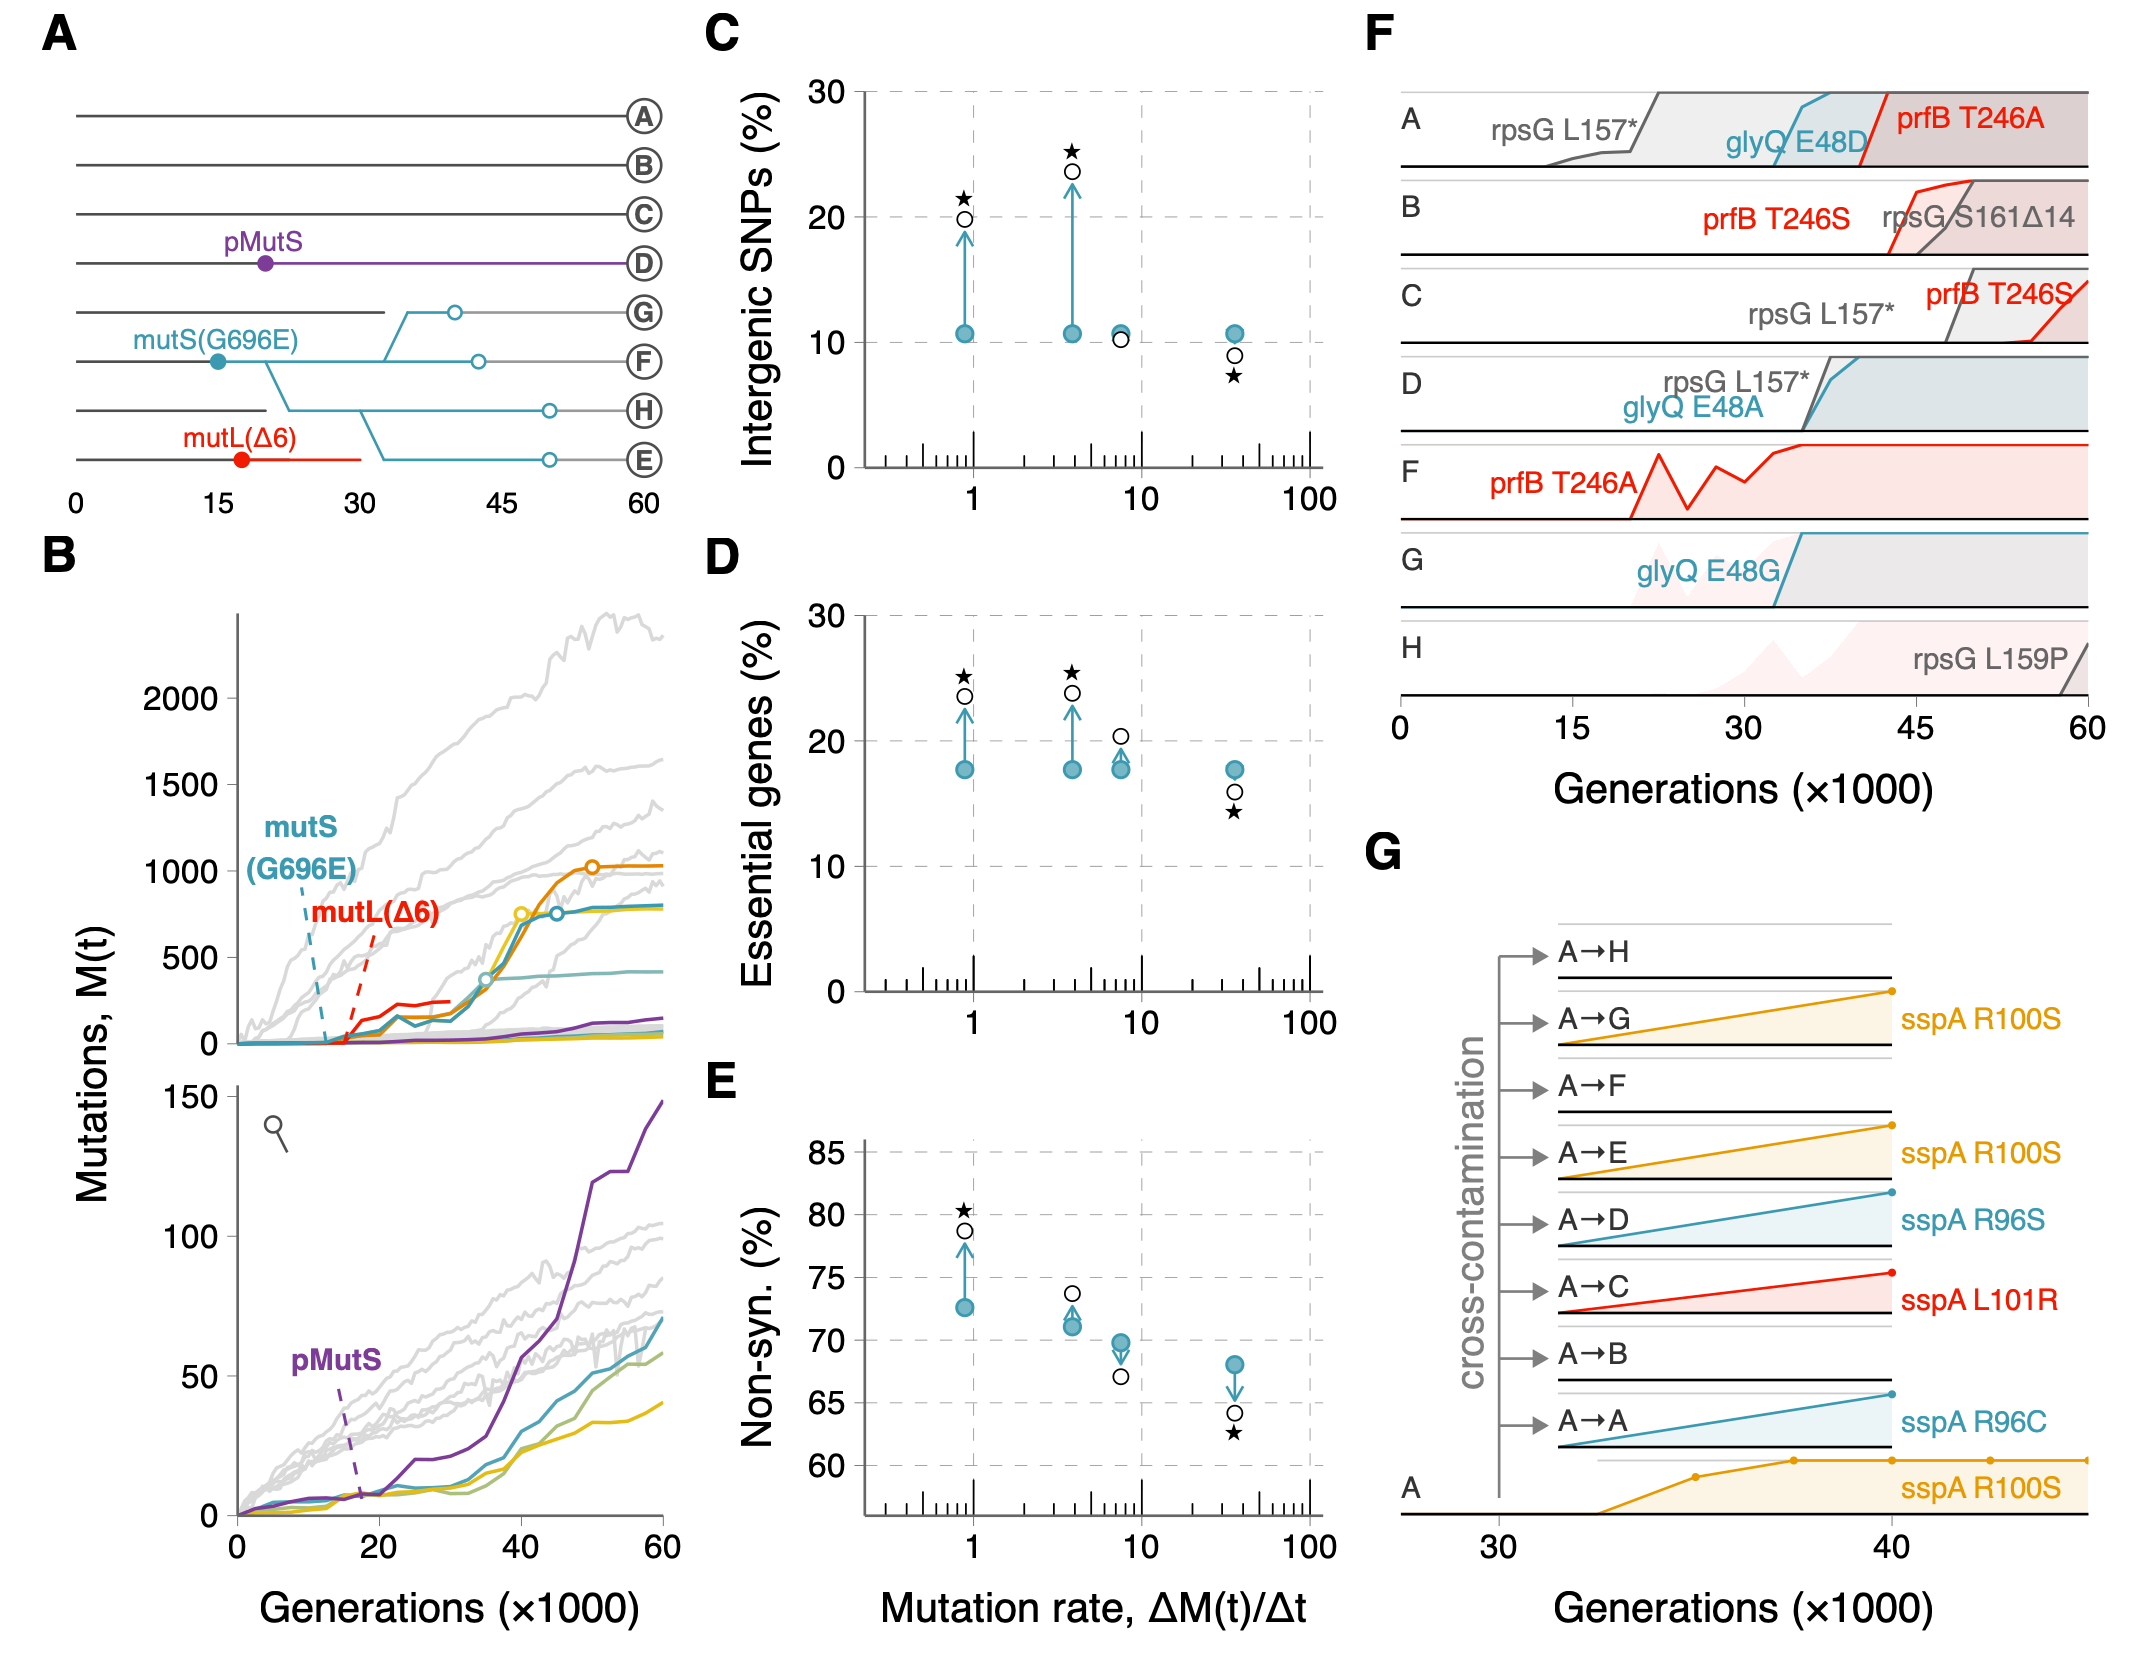

In [6]:
size(5.6, 7.1)

# Draw a magnifier
zoom_lwd = 0.3
zoom_col = 'grey30'
zoom_handle = annotate(geom='segment', x = 5, y = 140, xend = 7, yend = 130, lwd=zoom_lwd, col=zoom_col)
zoom_symbol = annotate(geom='point', x = 5, y = 140, pch=21, fill=w, stroke=zoom_lwd*1.5, col=zoom_col)

mutators = (
    free(overview + labs(tag='A')) /
    (daf_mutators + labs(tag='B')) /
    (daf_nonmutators + zoom_handle + zoom_symbol)
) + plot_layout(heights = c(1, 1, 1), axes='collect')

# mutators2 = (
#     (daf_mutators + labs(tag='B')) /
#     (daf_nonmutators + zoom_handle + zoom_symbol) /
#     free(as.ggplot(overview)) + labs(tag='A')
# ) + plot_layout(heights = c(1.4, 1, 1), axes='collect')

enrichments =
(
    (ig_enrichment + labs(x='Mutation rate, ΔM(t)/Δt', tag='C')) / 
    (ess_enrichment + labs(x='Mutation rate, ΔM(t)/Δt', tag='D')) / 
    (syn_enrichment + labs(x='Mutation rate, ΔM(t)/Δt', tag='E'))
) + plot_layout(axis_titles = 'collect')

convergence = (
    (domestication_scars + labs(tag='F')) /
    (A_takeover_sspA + labs(tag='G'))
)

(mutators | enrichments | convergence) + plot_layout(widths = c(0.65, 0.70, 1.05)) & theme(plot.tag = letters(-10, 0, 10, 0))
psave('output/genomics')

## Supp mutators

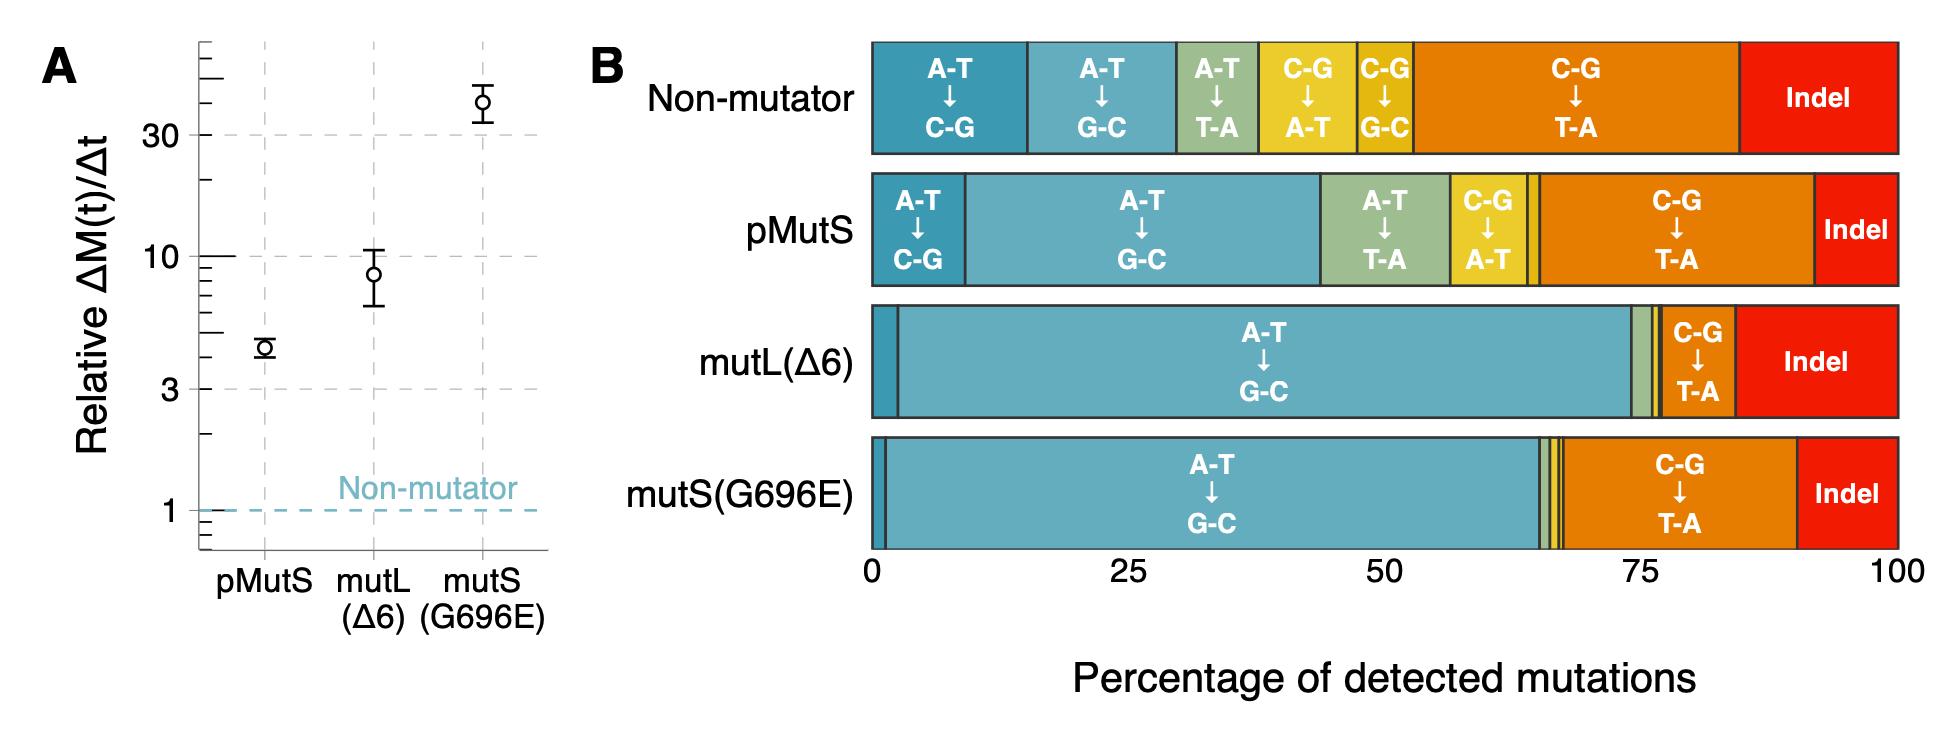

In [7]:
library(errors)
deltaM_deltat = readRDS('../analysis/genomics/07_mutation_statistics/Plots/GG/deltaM_deltat.rds')
mutation_spectrum = readRDS('../analysis/genomics/06_mutators/Plots/GG/mutation_spectrum.rds')
#fluctuation = readRDS('~/Sysbio/Mutator/Mutation rate measurements/21-11-26 Fluctuation in exponential phase/Plots/GG/mutS_mutation_rates.rds')


#spectrum_changes = readRDS('../analysis/genomics/06_mutators/Plots/GG/absolute_spectrum_changes.rds')
#spectrum_changes_lab = spectrum_changes + labs(tag='B') + theme(strip.text = element_text(size=9, face='bold'))

size(2.5, 6.5)

# (
#     (spectrum_changes_lab)
# ) / (
# ) & theme(plot.tag = letters(-5, 0, -10, 0))

((
    free(deltaM_deltat + labs(tag='A'), side='t')
) | (
    (mutation_spectrum + labs(tag='B'))
)) + plot_layout(widths = c(1, 3)) & theme(plot.tag = letters(-5, 0, -10, 0))

psave('output/supp_mutators')

## Supp structural variants

In [8]:
inversion_in_F = readRDS('../analysis/chromosome_replication/coverage_analysis/Plots/GG/inversion_in_F.rds')
flhD = readRDS('../analysis/genomics/02_structural_variation/Plots/GG/IS5_flhD.rds')
deletions = readRDS('../analysis/genomics/02_structural_variation/Plots/GG/deletions.rds')

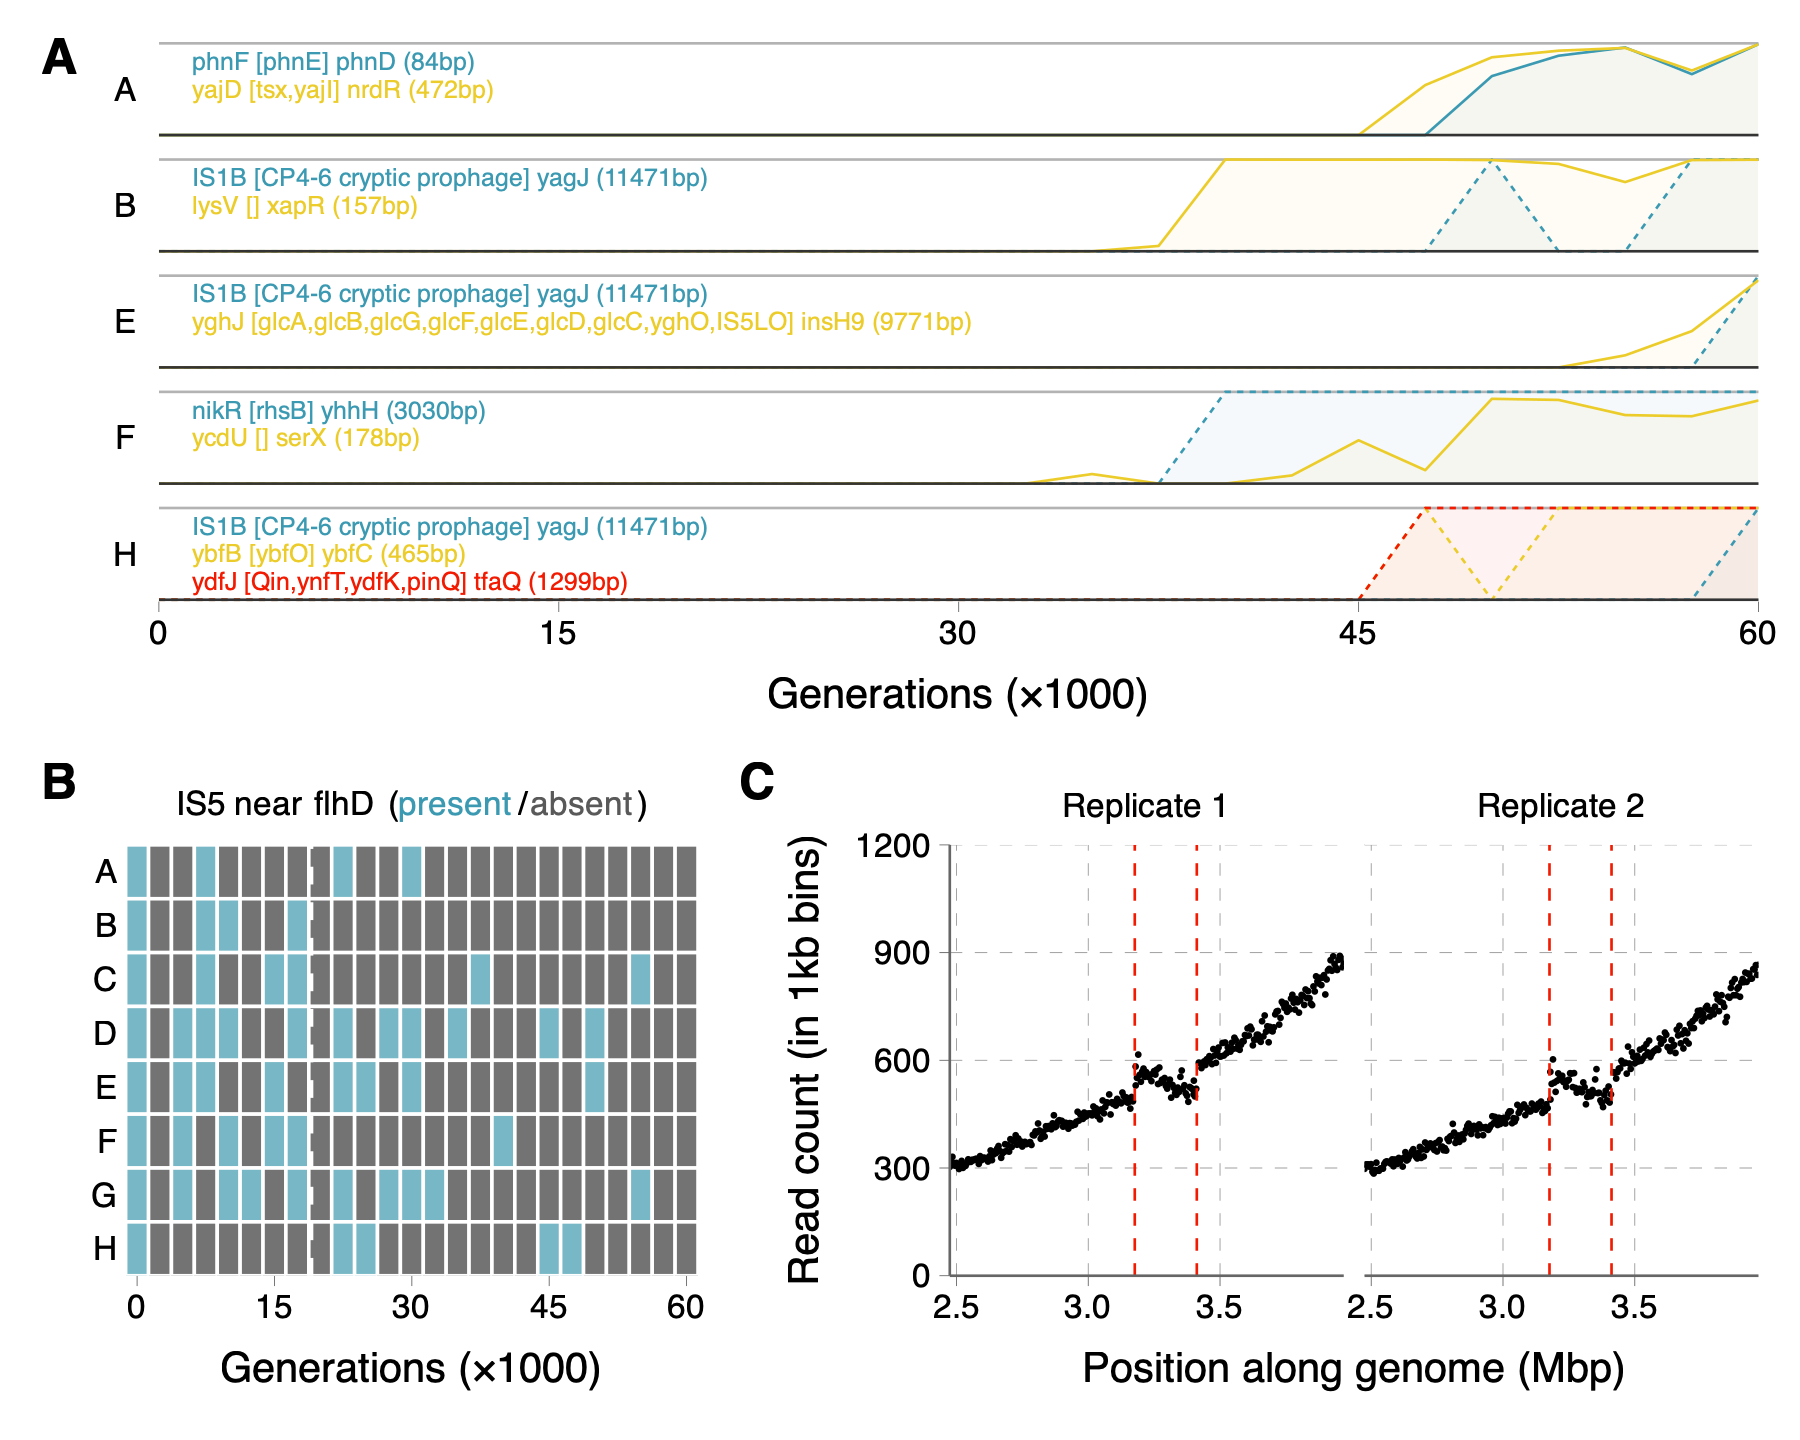

In [9]:
library(ggtext)

size(4.8, 6)

(
    (deletions)
) / (
    (
        free(flhD, side='l') | inversion_in_F
    ) + plot_layout(widths=c(1, 1.5))
) + 
    plot_layout(heights=c(1.3, 1)) +
    plot_annotation(tag_levels = 'A') & theme(plot.tag = letters(-5,4,-8,0))

psave('output/supp_structural')

# Trade-offs

In [10]:
stationary_survival = readRDS('../analysis/stationary_survival/GG/survival_by_population_ribbon_one_row.rds')
survival_auc_vs_mutations = readRDS('../analysis/stationary_survival/GG/survival_auc_vs_mutations.rds')
motility_vert_top = readRDS('../analysis/adhesion/motility_summary/Plots/GG/motility_tile_vert_top.rds')

In [11]:
dynamics = readRDS('../analysis/growth_curves/2024-06-11_beta/Plots/GG/growth_rate_vs_od_all_pure.rds')

In [12]:
width_expo_vs_stat = readRDS('../analysis/morphology/Plots/GG/width_expo_vs_stat.rds')
length_expo_vs_stat = readRDS('../analysis/morphology/Plots/GG/length_expo_vs_stat.rds')
stat_morphology_vs_mutations = readRDS('../analysis/morphology/Plots/GG/stat_morphology_vs_mutations.rds')

`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


`height` was translated to `width`.


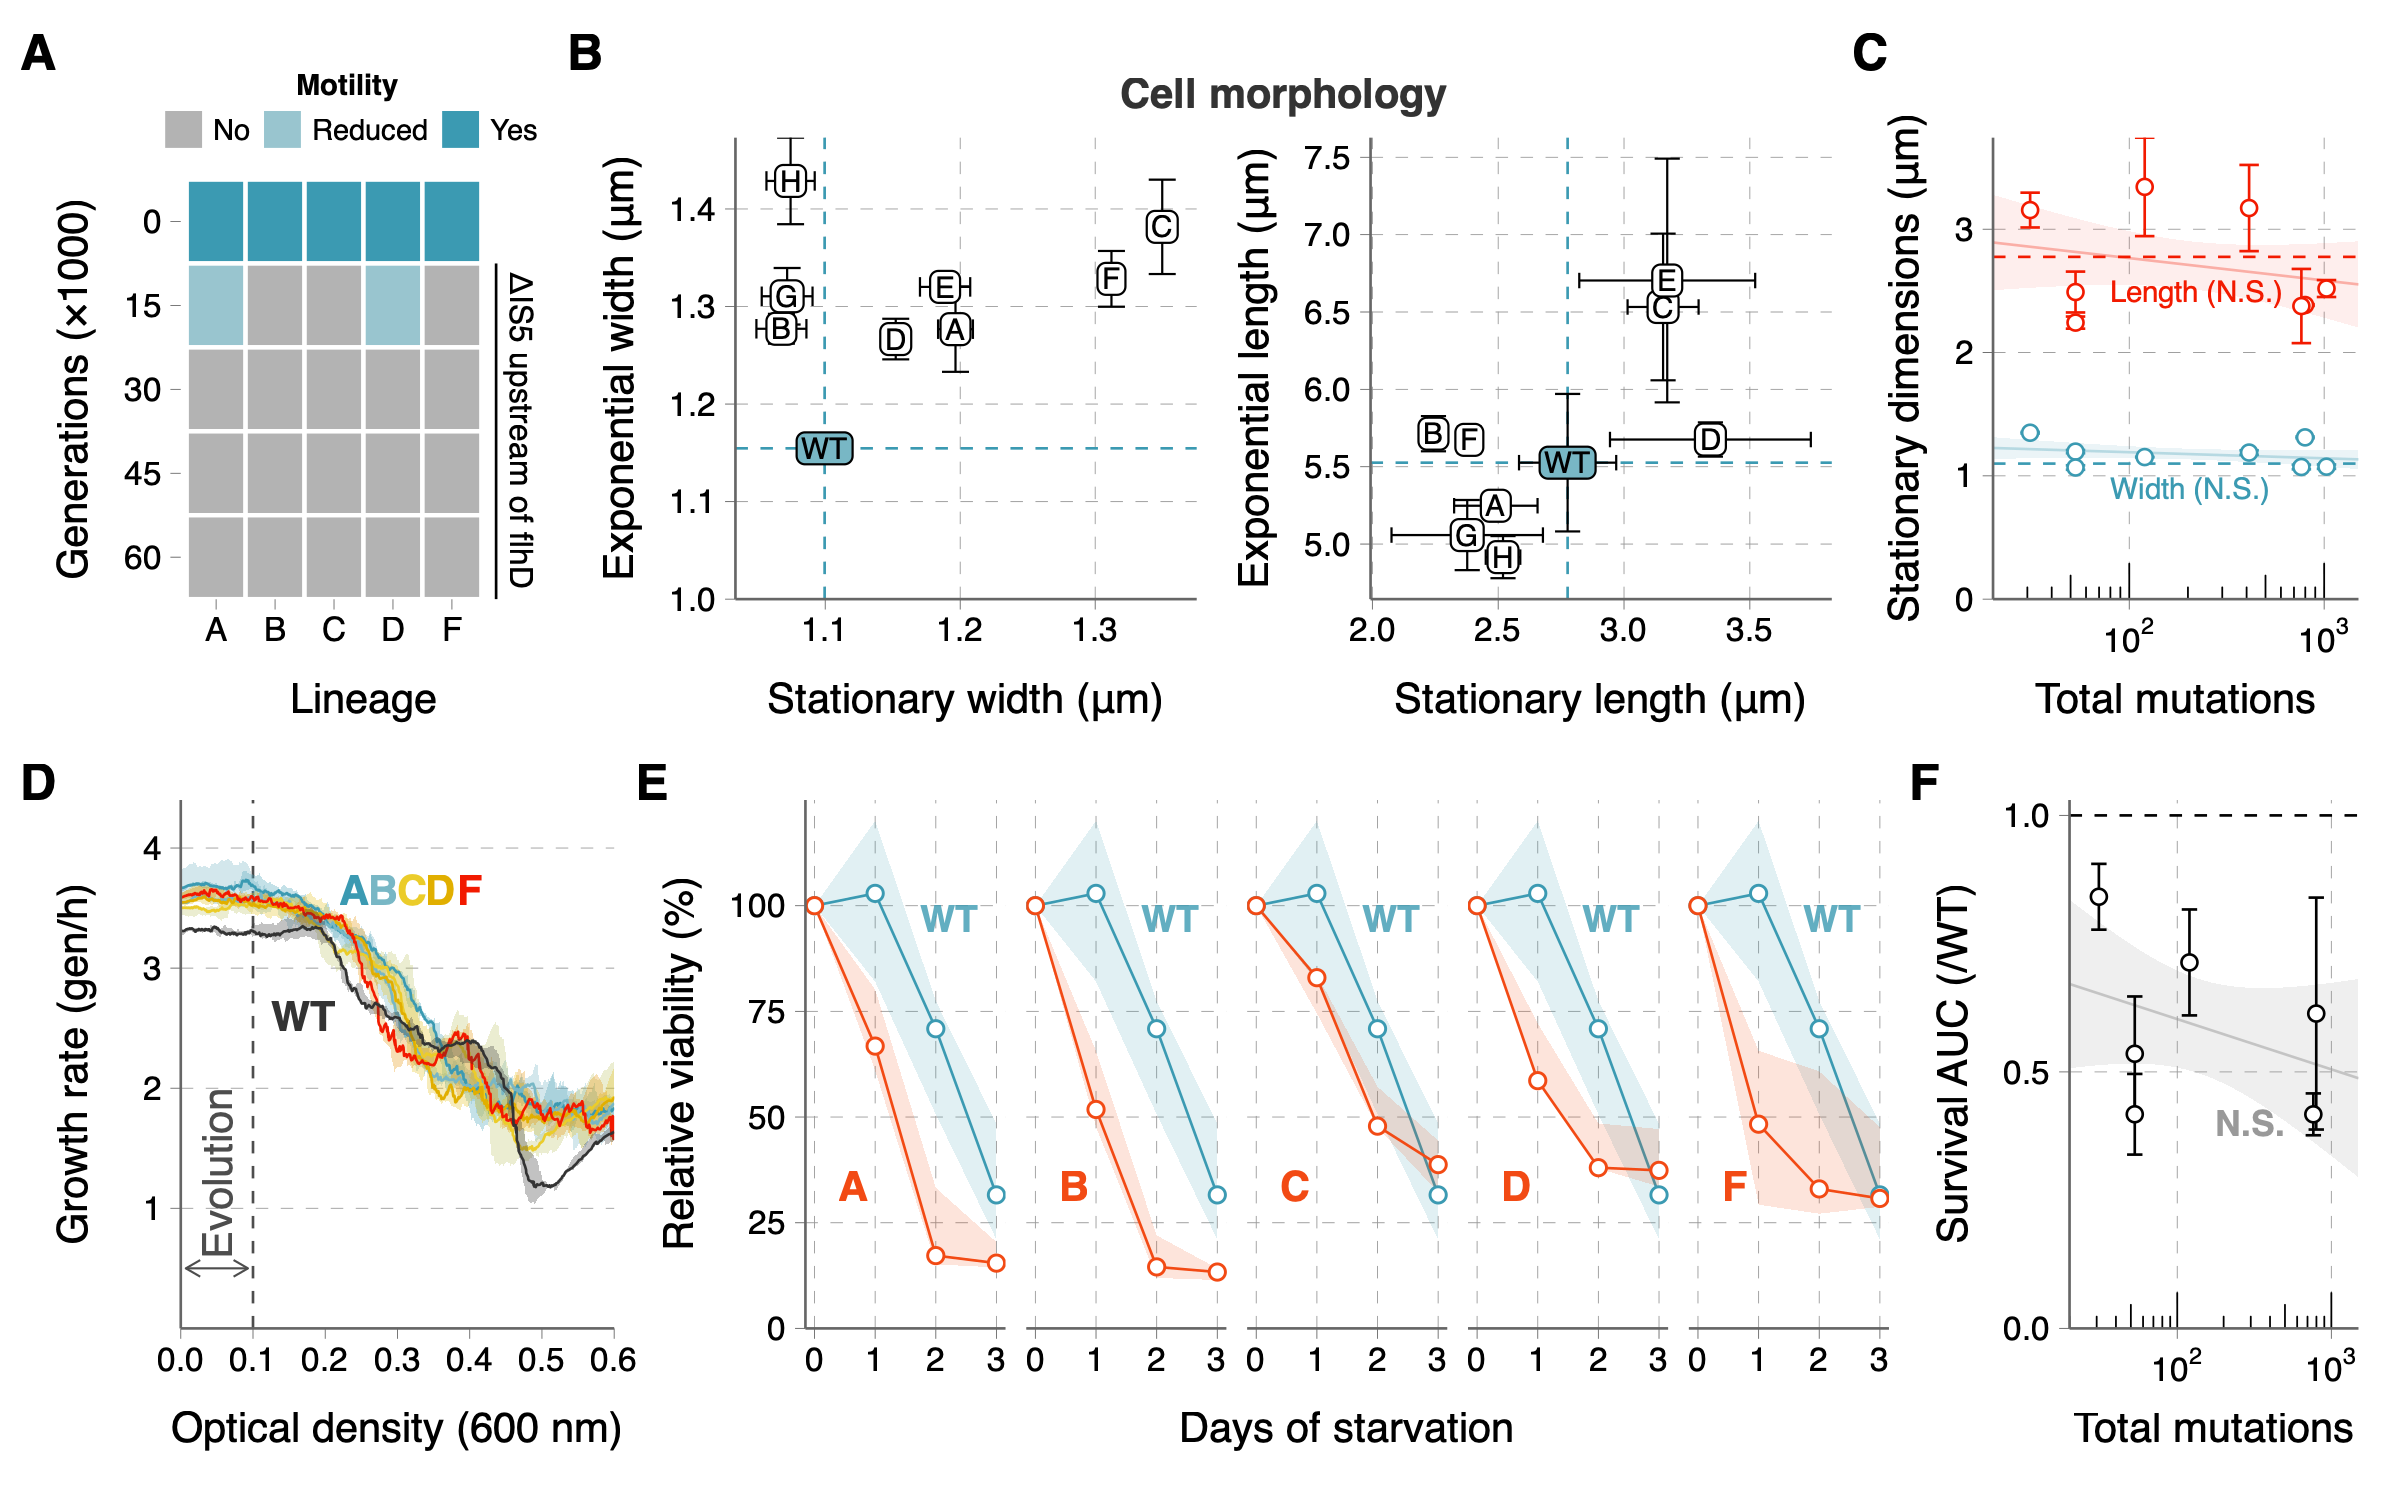

In [13]:
size(5, 8)

# Titles above panels B and C sit in strips spanning their columns, so the panels stay aligned
strip_title = function(label) ggplot() + theme_void() +
    annotate('text', x = 0.5, y = 0.5, label = label, fontface = 'bold', size = 10 / .pt, colour = 'grey20') +
    xlim(0, 1) + ylim(0, 1)
title_height = c(0.1, 1)

morphology = ((strip_title('Cell morphology') + labs(tag = 'B')) / (width_expo_vs_stat | length_expo_vs_stat)) +
    plot_layout(heights = title_height)
c_column = ((strip_title('') + labs(tag = 'C')) / stat_morphology_vs_mutations) + plot_layout(heights = title_height)

top = (
    free(motility_vert_top + labs(tag='A'), side='t') |
    morphology |
    c_column
) + plot_layout(widths = c(1, 3, 1))

bottom = (
    (dynamics + labs(tag='D')) |
    (stationary_survival + labs(tag='E')) |
    (survival_auc_vs_mutations + labs(tag='F'))
) + plot_layout(widths=c(1.2, 3, 0.8))

(
    top / bottom
) +
    plot_layout(heights=c(1,1)) & theme(plot.tag = letters(-5, 0, 0, -5))

psave('output/latent_traits')

# Chromosome replication

In [14]:
read_counts = readRDS('../analysis/chromosome_replication/coverage_analysis/Plots/GG/locus_copy_numbers.rds')
replication_times = readRDS('../analysis/chromosome_replication/coverage_analysis/Plots/GG/replication_times.rds')
fork_velocity = readRDS('../analysis/chromosome_replication/coverage_analysis/Plots/GG/fork_velocity.rds')

labels_short = c('W'='WT', 'R'='rpoS*', 'B'='B', 'F'='F')

multifork_sketch = as.ggplot(image_read('static/multifork_replication_sketch.png'))

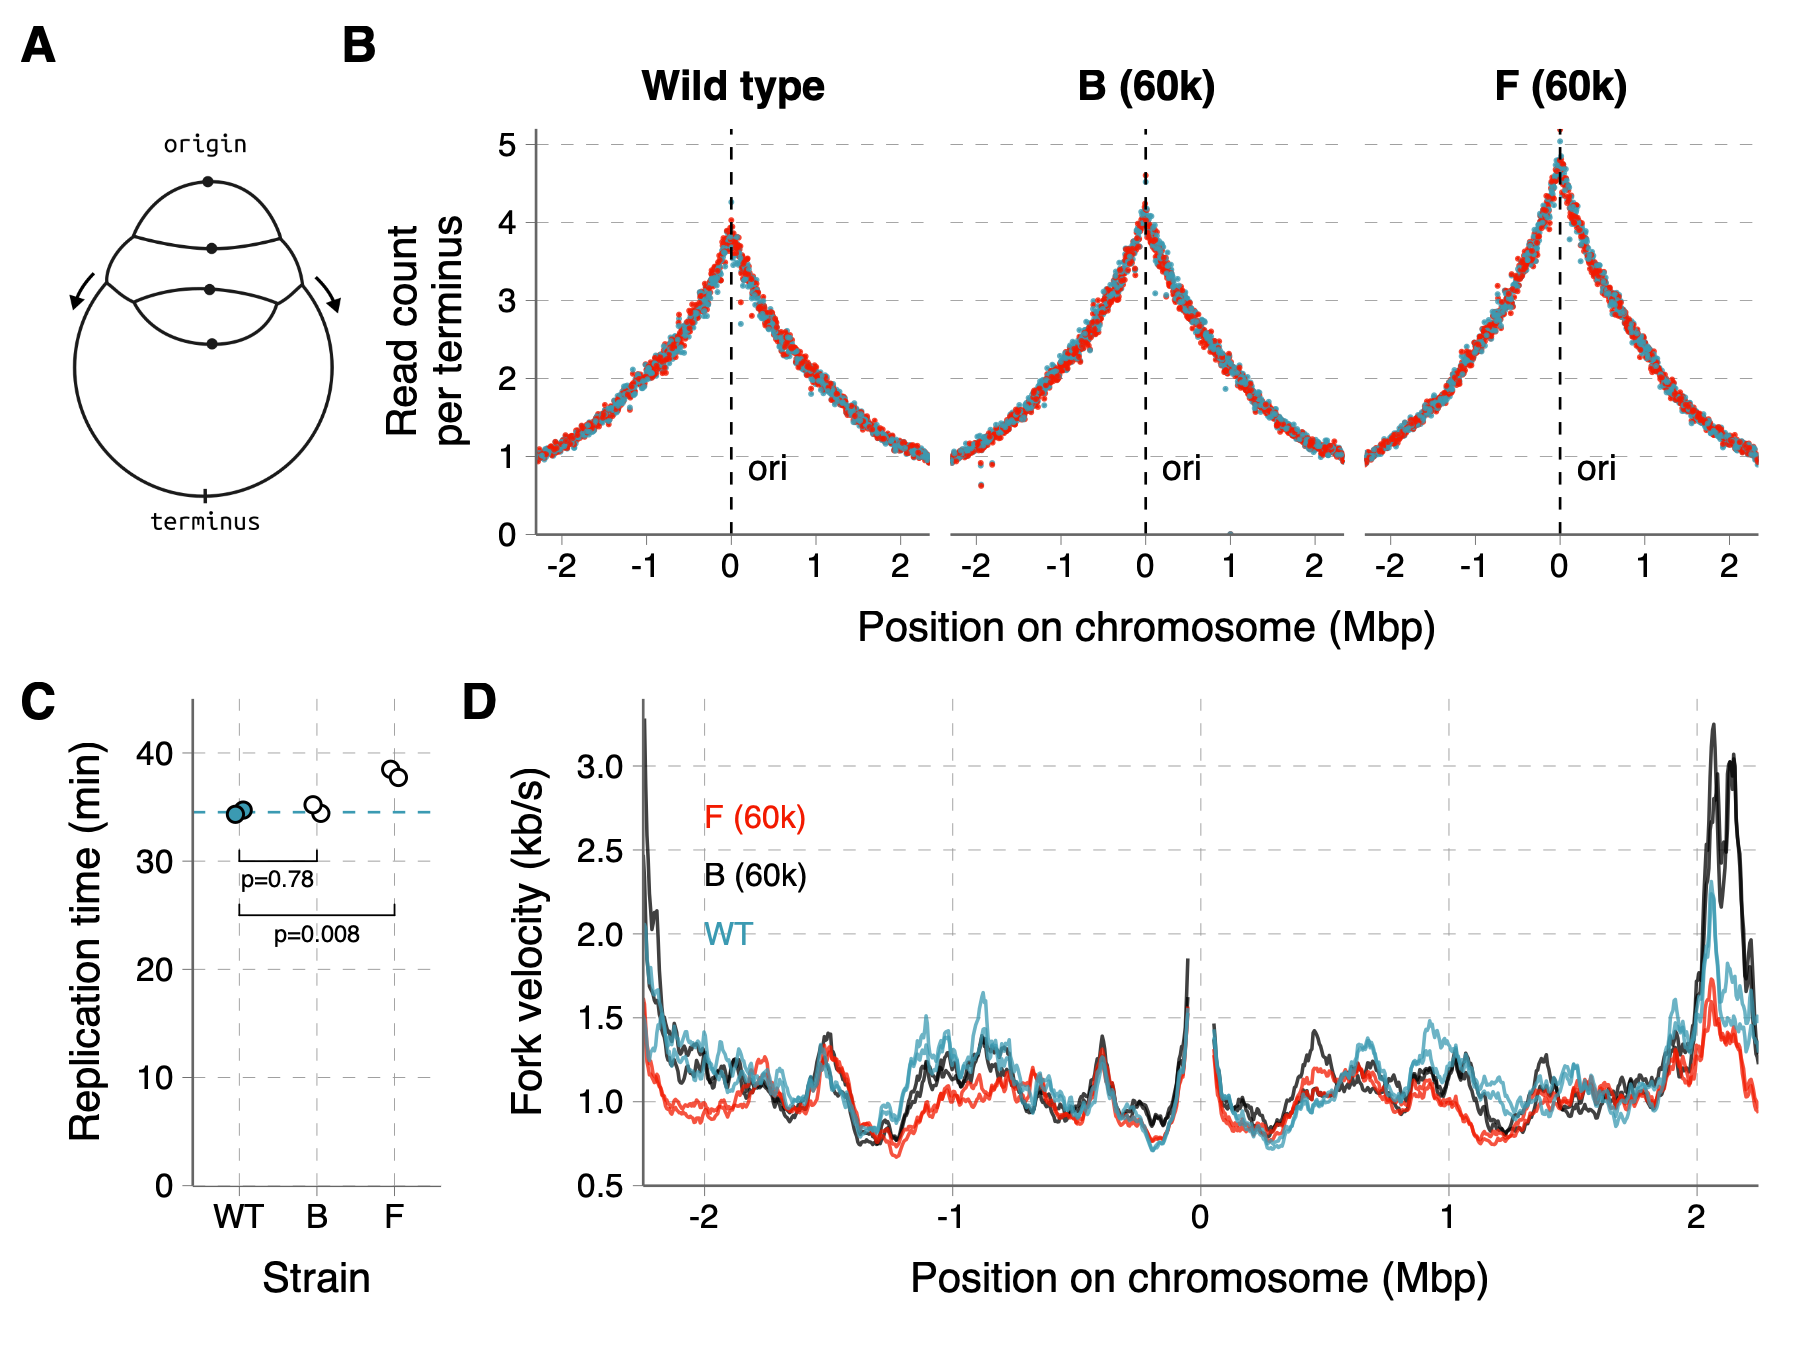

In [15]:
no_x_axis = theme(axis.title.x=eb, axis.text.x=eb)

size(4.5, 6)

counts = (
    read_counts
    )# / (
    #replication_lags + small_text + small_titles
#)

(
    (
        (multifork_sketch | counts) + plot_layout(widths=c(1,4.5))
    ) / (
        (
            free(replication_times + labs(y='Replication time (min)'), side='l') | 
            fork_velocity + small_text + small_titles + labs(y='Fork velocity (kb/s)')
        ) + plot_layout(widths=c(1,3))
    )
) + 
    plot_layout(heights=c(1, 1.2)) +
    plot_annotation(tag_levels = 'A') & theme(plot.tag = letters(-10, 3, -5, -5))

psave('output/chromosome_replication')

# Phages

In [10]:
fhuA_mutations = readRDS('../analysis/genomics/09_phage_fhuA/Plots/GG/fhuA_alleles_areas_1_col.rds')
attB_occupancy = readRDS('../analysis/genomics/09_phage_fhuA/Plots/GG/attachment_site_occupancy_pooled.rds')
phage_production_errorbars = readRDS('../analysis/phage/phage_production/Plots/GG/PFUs_errorbars.rds')

phage_genome_img = image_read("static/genome_plot.png")
phage_genome_plot = as.ggplot(phage_genome_img)

superinfection_img = image_read('static/montage_horiz.png')
superinfection_plot = as.ggplot(superinfection_img)

C_collapse = readRDS('../analysis/phage/phage_collapse/GG/C_collapse_23_10_10.rds')

library(ggtext)

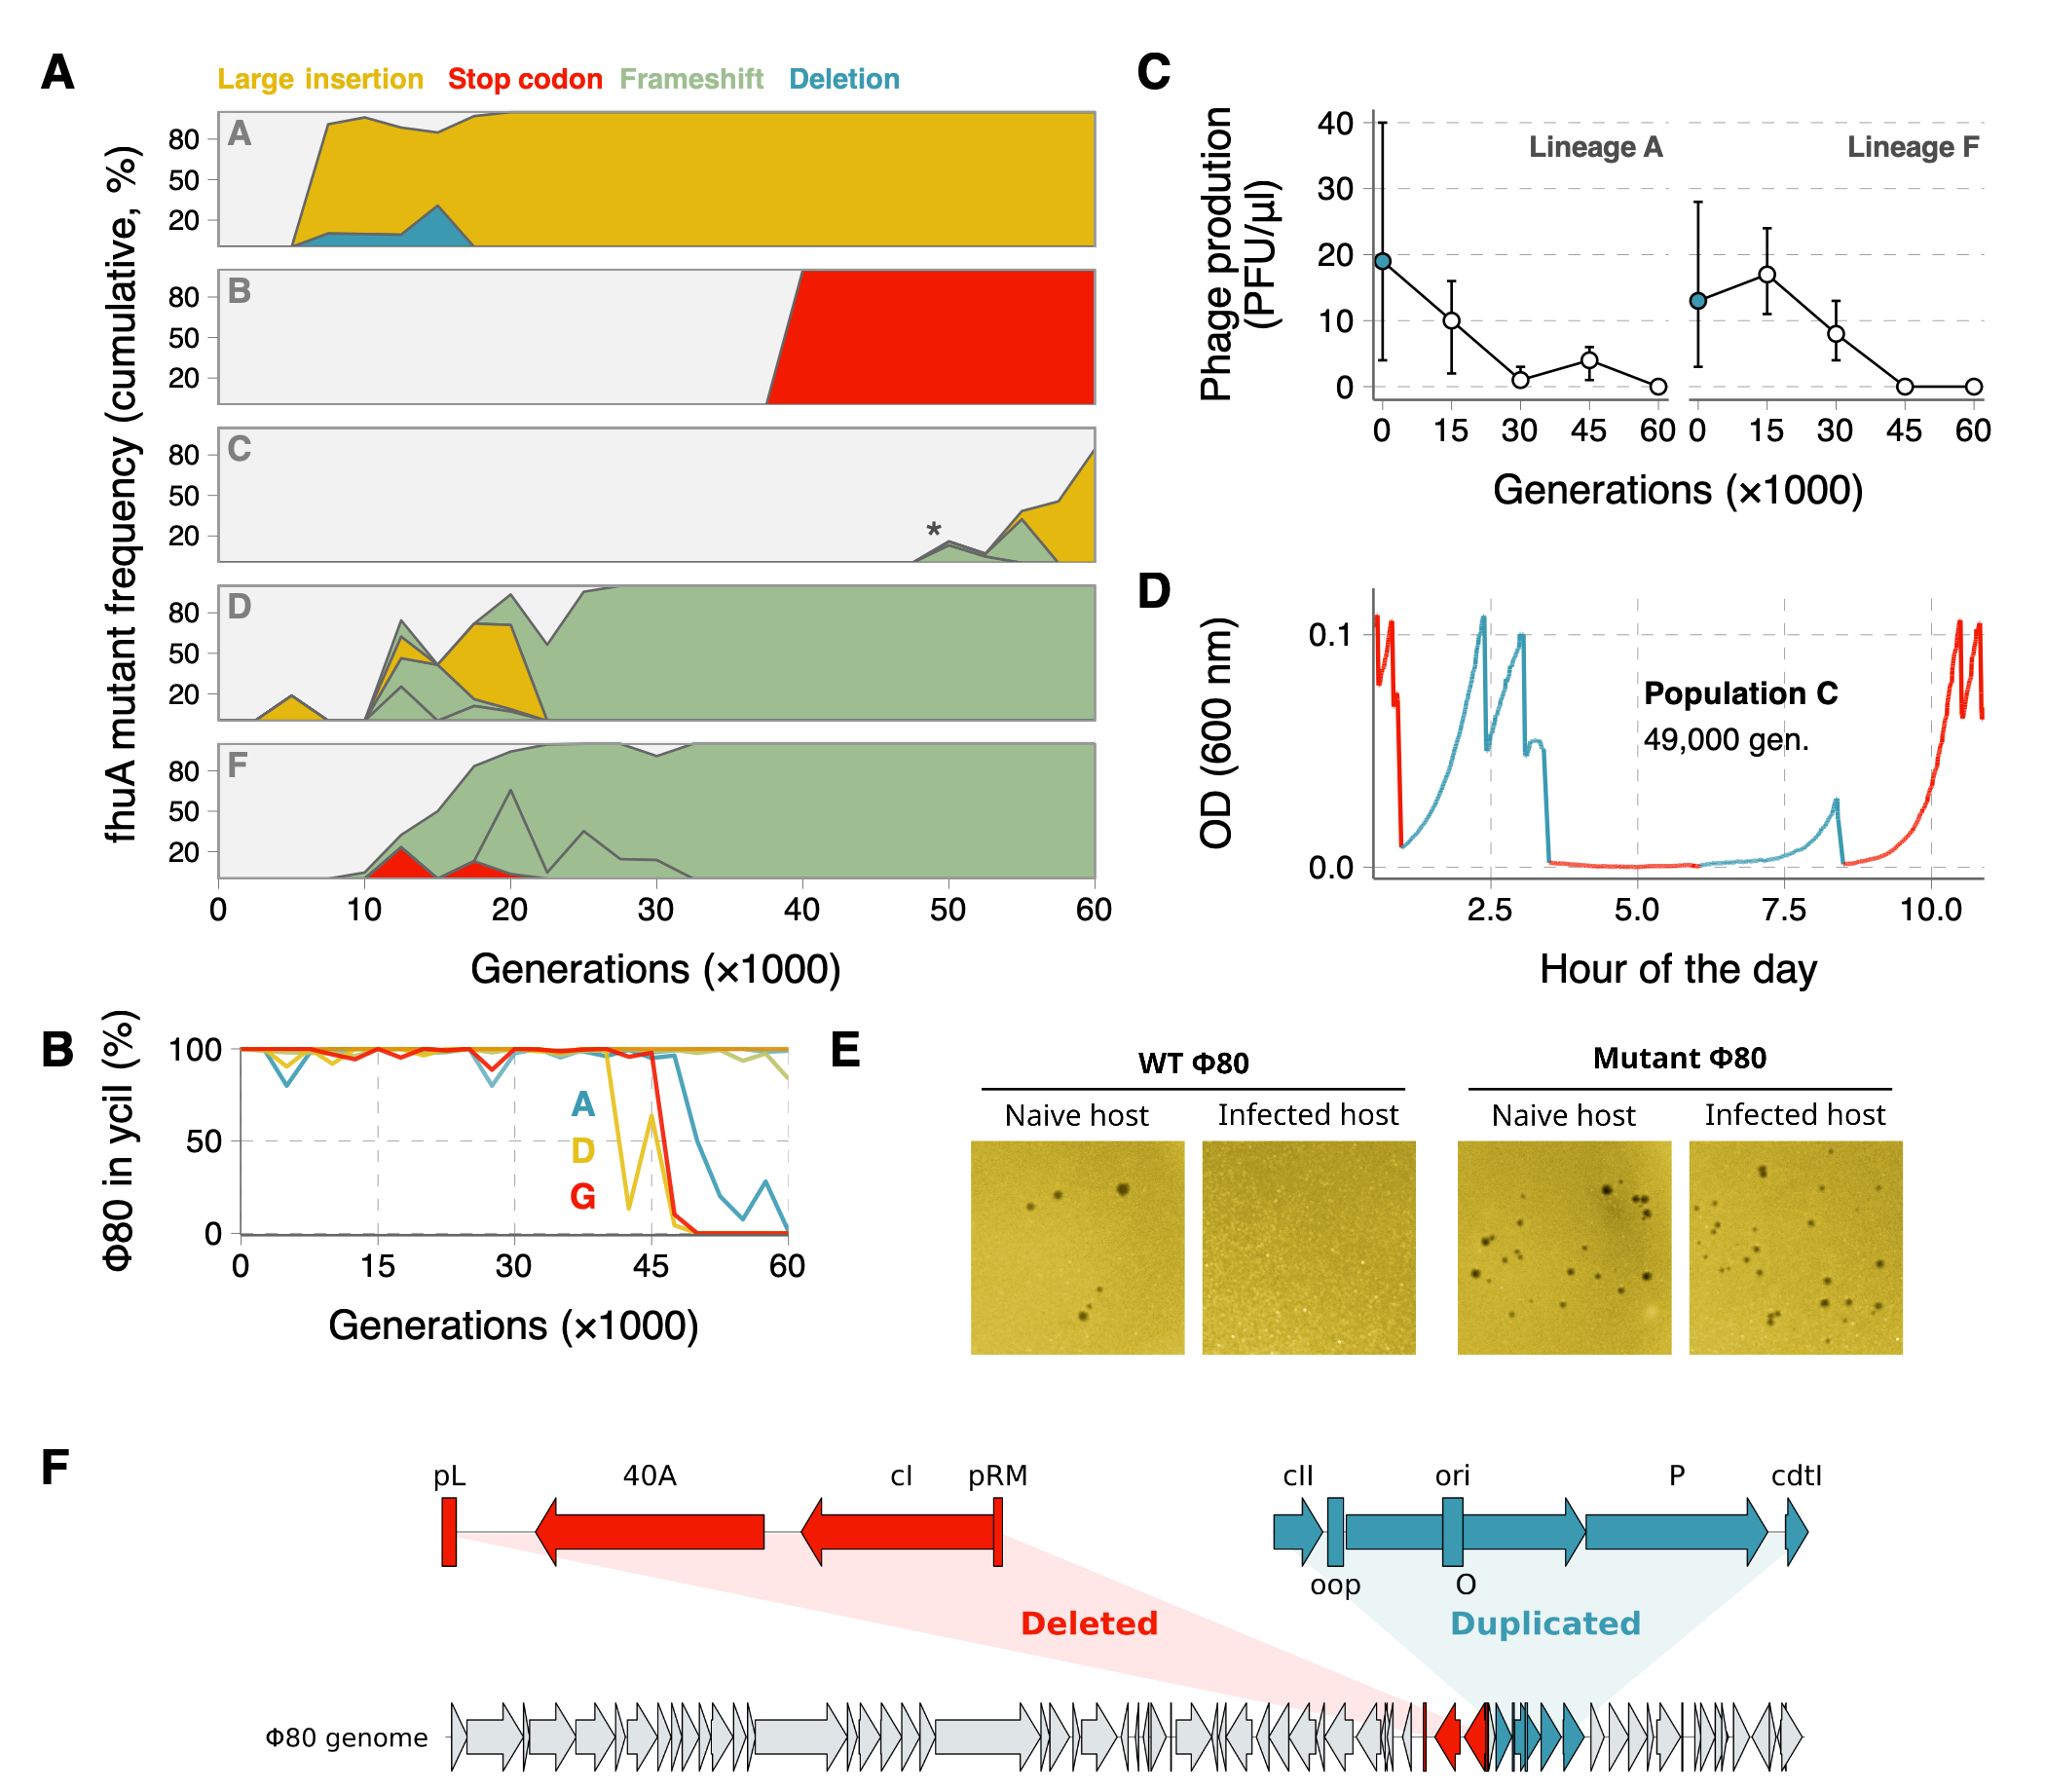

In [11]:
size(6 + 40/300, 7) # + height of panel A's legend

attB_occupancy_margin = attB_occupancy + theme(plot.margin = margin(0,10,0,0))

top = (
    (
        free(fhuA_mutations + small_titles + small_text, side='l') + labs(tag='A')
    ) | (
        (phage_production_errorbars + labs(tag='C')) / (C_collapse + small_titles + labs(tag='D'))
    )
) + plot_layout(widths = c(1.4, 1))

center = (
    free(attB_occupancy_margin, side='b') + labs(y='Φ80 in yciI (%)', tag='B') | (superinfection_plot + theme(plot.margin = margin(0,0,20,0)) + labs(tag='E'))
) + plot_layout(widths = c(1,2))

bottom = (
    free(phage_genome_plot + labs(tag='F')) + theme(plot.margin = margin(0,10,0,0))
)

(
    top / center / bottom
) + 
    plot_layout(heights=c(3.75, 1.5, 1.5)) &
    theme(plot.tag = letters(0,7,-5,0))

psave('output/phage')

## Supp phage

In [18]:
still_sensitive = readRDS('../analysis/phage/C20-21_resistance/Plots/GG/C20-21_still_has_sensitive_cells.rds')

mutator_labels = c('mutS_1'='mutS(G696E)', 'mutL_1'='mutL(Δ6)', 'ygbA/mutS_1'='pMutS')
fhuA_vs_mutators = readRDS('../analysis/genomics/10_mutation_traces/Plots/GG/fhuA_vs_mutators.rds')

attB_occupancy_in_D = readRDS('../analysis/genomics/09_phage_fhuA/Plots/GG/attachment_site_occupancy_D_all_sites.rds')

In [19]:
fhuA_vs_mutators_bold = fhuA_vs_mutators + theme(strip.text = element_text(face='bold', margin=margin(0,4,4,0)))

Don't know how to automatically pick scale for object of type <difftime>.
Defaulting to continuous.


Warning message:
“Removed 320 rows containing missing values or values outside the scale range
(`geom_line()`).”


Don't know how to automatically pick scale for object of type <difftime>.
Defaulting to continuous.


Warning message:
“Removed 320 rows containing missing values or values outside the scale range
(`geom_line()`).”


Don't know how to automatically pick scale for object of type <difftime>.
Defaulting to continuous.


Warning message:
“Removed 320 rows containing missing values or values outside the scale range
(`geom_line()`).”


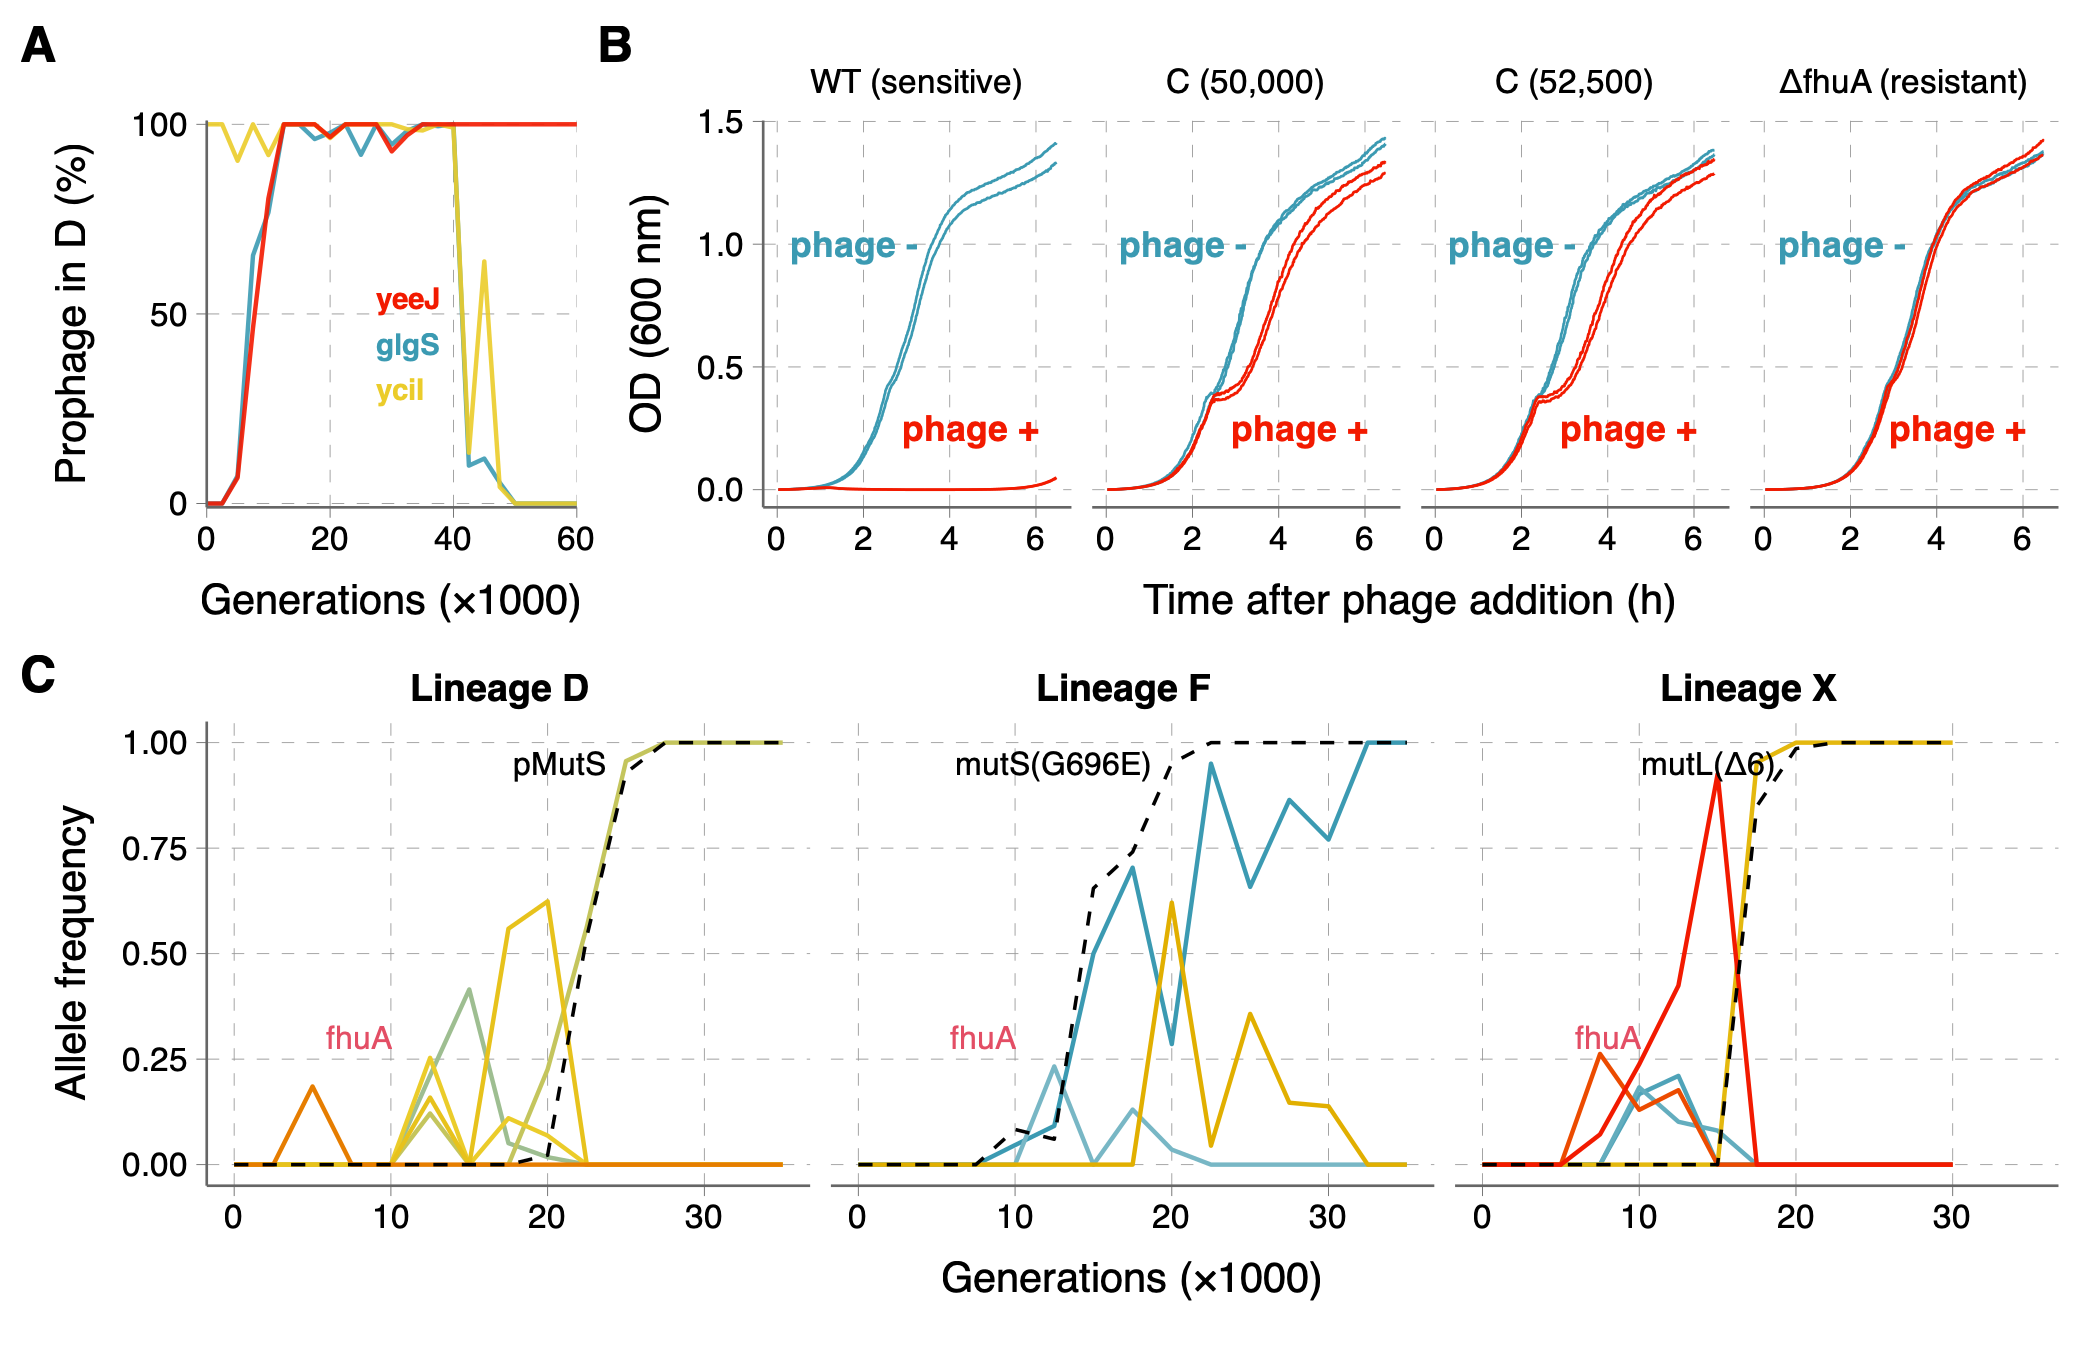

In [20]:
size(4.5, 7)

(
    (
        (attB_occupancy_in_D | still_sensitive) + plot_layout(widths=c(1, 3.5))
    ) /
    fhuA_vs_mutators_bold
) +
    plot_layout(heights=c(1, 1.2)) +
    plot_annotation(tag_levels = 'A') & theme(plot.tag = letters(-10, 0, -5, -5))

psave('output/supp_phage')

# Separate growth dynamics

In [21]:
separate_dynamics_A = readRDS('../analysis/growth_curves/2025-03-23_AF_gamma/Plots/GG/separate_dynamics_A.rds')
separate_dynamics_F = readRDS('../analysis/growth_curves/2025-03-23_AF_gamma/Plots/GG/separate_dynamics_F.rds')

separate_dynamics_B = readRDS('../analysis/growth_curves/2025-04-05_BC_alpha/Plots/GG/separate_dynamics_B.rds')
separate_dynamics_C = readRDS('../analysis/growth_curves/2025-04-05_BC_alpha/Plots/GG/separate_dynamics_C.rds')

separate_dynamics_D = readRDS('../analysis/growth_curves/2025-04-15_DE_alpha/Plots/GG/separate_dynamics_D.rds')

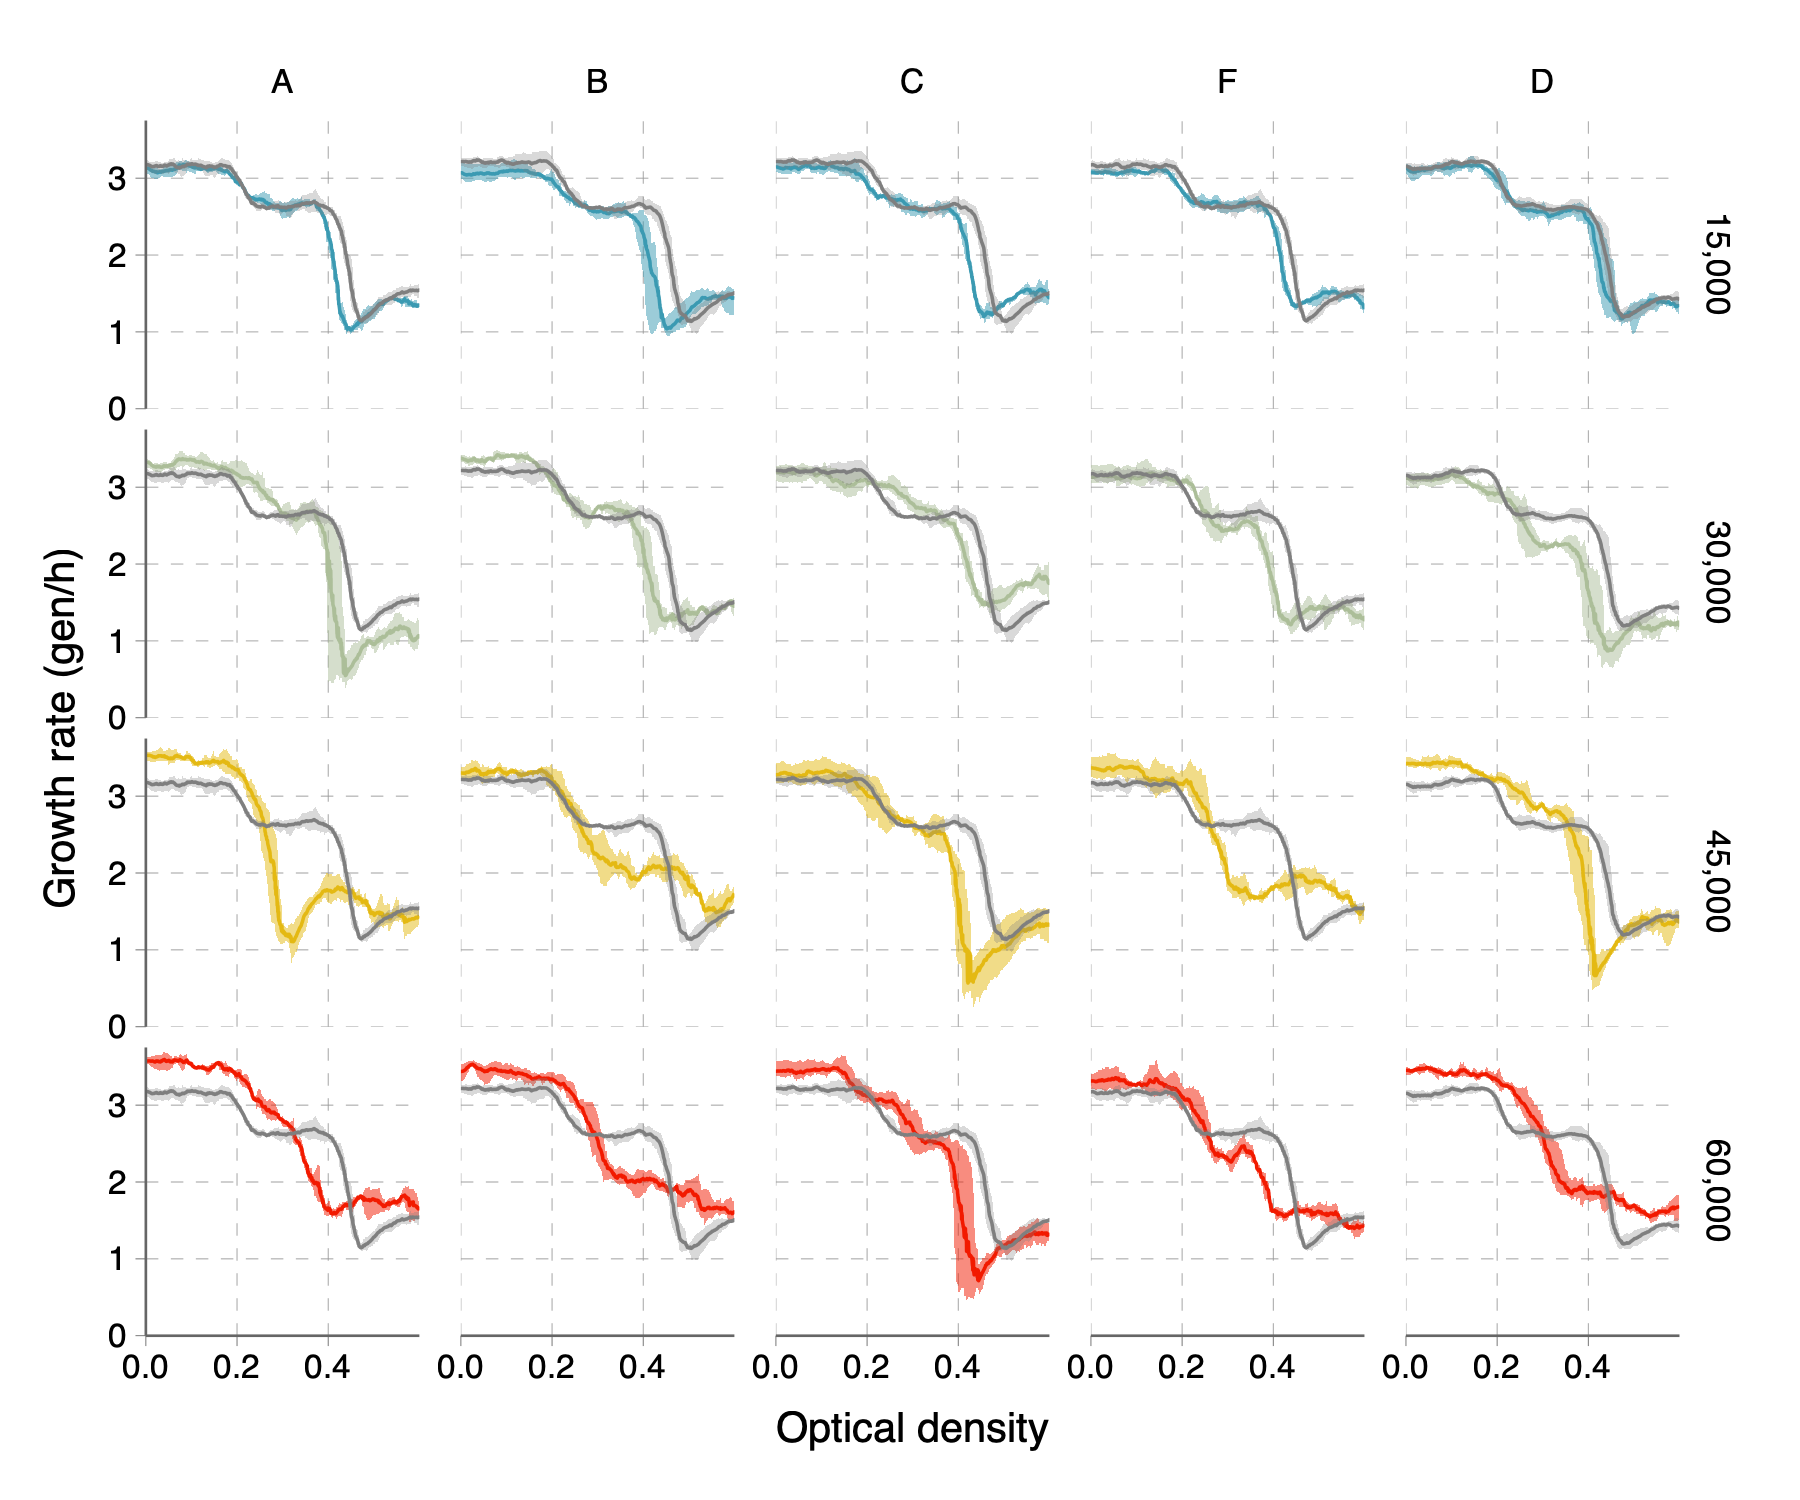

In [22]:
size(5, 6)

no_strip_title = theme(strip.text.y = eb)

(
    (separate_dynamics_A + no_strip_title) |
    (separate_dynamics_B + no_strip_title) |
    (separate_dynamics_C + no_strip_title) |
    (separate_dynamics_F + no_strip_title) |
    (separate_dynamics_D)
) + 
    plot_layout(axes='collect')

psave('output/separate_dynamics')